In [ ]:
from google.colab import files

# Ask the user to upload a file at runtime
uploaded = files.upload()

# Get the uploaded filename
file_path = next(iter(uploaded))

print("Uploaded file:", file_path)

Saving IPL dataset final.csv to IPL dataset final.csv
Uploaded file: IPL dataset final.csv


In [ ]:
print(df.info())
print(df.describe())
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 182 entries, 0 to 181
Data columns (total 59 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Player         182 non-null    object 
 1   Country        182 non-null    object 
 2   Team           182 non-null    object 
 3   AGE            182 non-null    int64  
 4   CAPTAINCY EXP  182 non-null    int64  
 5   PAYING_ROLE    182 non-null    float64
 6   MAT            182 non-null    int64  
 7   INNS           182 non-null    float64
 8   RUNS           182 non-null    float64
 9   BF             182 non-null    float64
 10  HS             182 non-null    float64
 11  AVG            182 non-null    float64
 12  SR             182 non-null    float64
 13  NO             182 non-null    float64
 14  4S             182 non-null    float64
 15  6S             182 non-null    float64
 16  0S             182 non-null    float64
 17  50S            182 non-null    float64
 18  100S      

In [ ]:
# ============================================
# 1. BASIC DATASET OVERVIEW
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Dataset Shape:", df.shape)
print("Number of Players:", df["Player"].nunique())
print("Number of Countries:", df["Country"].nunique())
print("Number of Teams:", df["Team"].nunique())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types:")
display(df.dtypes.value_counts())

print("\nMissing Values:")
missing = df.isnull().sum()
display(missing[missing > 0])

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (182, 59)
Number of Players: 182
Number of Countries: 9
Number of Teams: 10

Duplicate Rows: 0

Data Types:


,count
float64,50
object,3
int64,3
float32,3



Missing Values:


,0



First 5 Rows:


,Player,Country,Team,AGE,CAPTAINCY EXP,PAYING_ROLE,MAT,INNS,RUNS,BF,...,B_TSR,B_T4W,B_T5W,SOLD_PRICE,PCA1,PCA2,PCA3,UMAP1,UMAP2,UMAP3
0,Ruturaj Gaikwad,IND,CSK,26,0,0.0,36,36.0,1207.0,926.0,...,0.00,0.0,0.0,0.0,1.486922,-2.583087,0.819950,3.128599,6.795410,6.375290
1,Shivam Dube,IND,CSK,29,0,0.0,35,33.0,688.0,516.0,...,25.80,0.0,0.0,0.0,-0.146867,-0.486808,-1.054814,6.464762,8.013913,0.991378
2,Ambati Rayudu,IND,CSK,37,0,0.0,188,175.0,4190.0,3296.0,...,0.00,0.0,0.0,0.0,5.260047,-1.381564,5.267140,3.499169,6.424592,5.603557
3,Devon Conway,NZ,CSK,31,0,0.0,7,7.0,252.0,173.0,...,0.00,0.0,0.0,0.0,2.995704,-1.986752,-2.243926,5.003771,7.506476,3.774961
4,Moeen Ali,ENG,CSK,35,0,0.0,44,42.0,910.0,632.0,...,19.74,0.0,0.0,0.0,4.362876,3.469731,-4.403745,6.379275,6.914082,1.278716


In [ ]:
# ============================================
# 2. COLUMN CATEGORIZATION
# ============================================

categorical_cols = [
    "Player",
    "Country",
    "Team"
]

derived_cols = [
    "PCA1",
    "PCA2",
    "PCA3",
    "UMAP1",
    "UMAP2",
    "UMAP3"
]

constant_cols = [
    col for col in df.columns
    if df[col].nunique() <= 1
]

print("Categorical Columns:")
print(categorical_cols)

print("\nDerived PCA/UMAP Columns:")
print(derived_cols)

print("\nConstant Columns:")
print(constant_cols)

Categorical Columns:
['Player', 'Country', 'Team']

Derived PCA/UMAP Columns:
['PCA1', 'PCA2', 'PCA3', 'UMAP1', 'UMAP2', 'UMAP3']

Constant Columns:
['PAYING_ROLE', 'SOLD_PRICE']


In [ ]:
# ============================================
# 3. ORIGINAL NUMERICAL FEATURES
# ============================================

exclude_cols = (
    categorical_cols
    + derived_cols
    + constant_cols
)

feature_cols = [
    col for col in df.columns
    if col not in exclude_cols
]

print("Number of original numerical features:", len(feature_cols))

print("\nFeatures:")
print(feature_cols)

Number of original numerical features: 48

Features:
['AGE', 'CAPTAINCY EXP', 'MAT', 'INNS', 'RUNS', 'BF', 'HS', 'AVG', 'SR', 'NO', '4S', '6S', '0S', '50S', '100S', 'TMAT', 'TINNS', 'TRUNS', 'TBF', 'THS', 'TAVG', 'TSR', 'TNO', 'T4S', 'T6S', 'T0S', 'T50S', 'T100S', 'B_INNS', 'B_BALLS', 'B_RUNS', 'B_MAIDENS', 'B_WKTS', 'B_AVG', 'B_ECON', 'B_SR', 'B_4W', 'B_5W', 'B_TINNS', 'B_TBALLS', 'B_TRUNS', 'B_TMAIDENS', 'B_TWKTS', 'B_TAVG', 'B_TECON', 'B_TSR', 'B_T4W', 'B_T5W']


In [ ]:
# ============================================
# 4. COUNTRY DISTRIBUTION
# ============================================

country_counts = df["Country"].value_counts()

print("Number of Countries:", len(country_counts))

display(country_counts)

Number of Countries: 9


,count
Country,
IND,118
WI,14
AUS,14
SA,11
NZ,9
ENG,8
SL,5
AFG,2
BAN,1


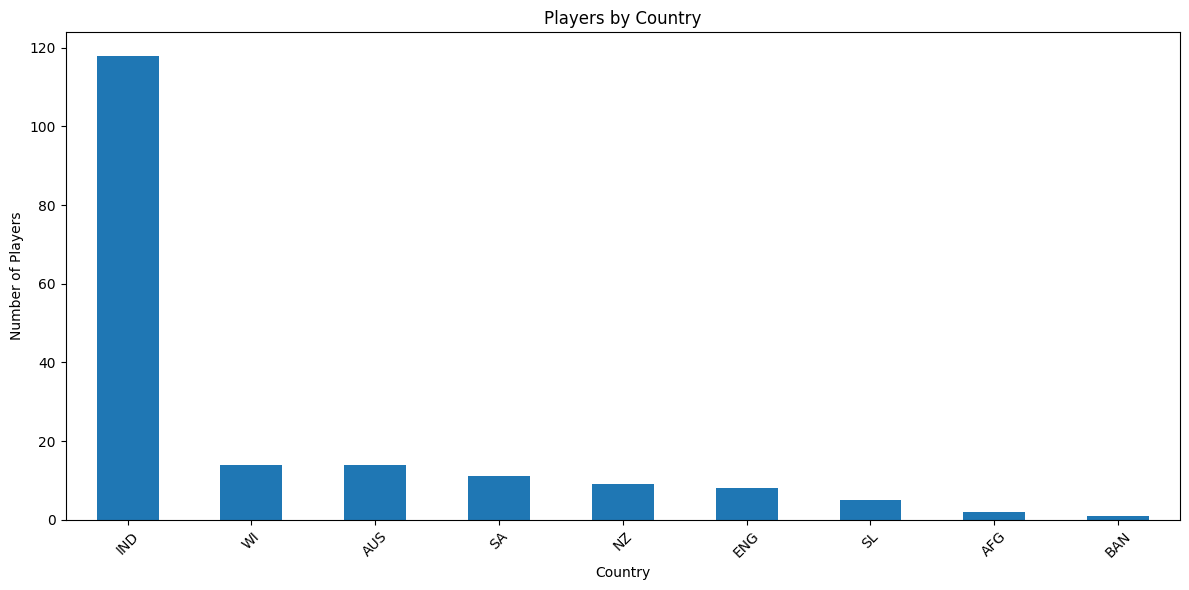

In [ ]:
plt.figure(figsize=(12, 6))

country_counts.plot(kind="bar")

plt.title("Players by Country")
plt.xlabel("Country")
plt.ylabel("Number of Players")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# 5. TEAM DISTRIBUTION
# ============================================

team_counts = df["Team"].value_counts()

print("Number of Teams:", len(team_counts))

display(team_counts)

Number of Teams: 10


,count
Team,
MI,21
KKR,20
SRH,19
PK,19
RR,18
CSK,18
GT,18
DC,17
LSG,17


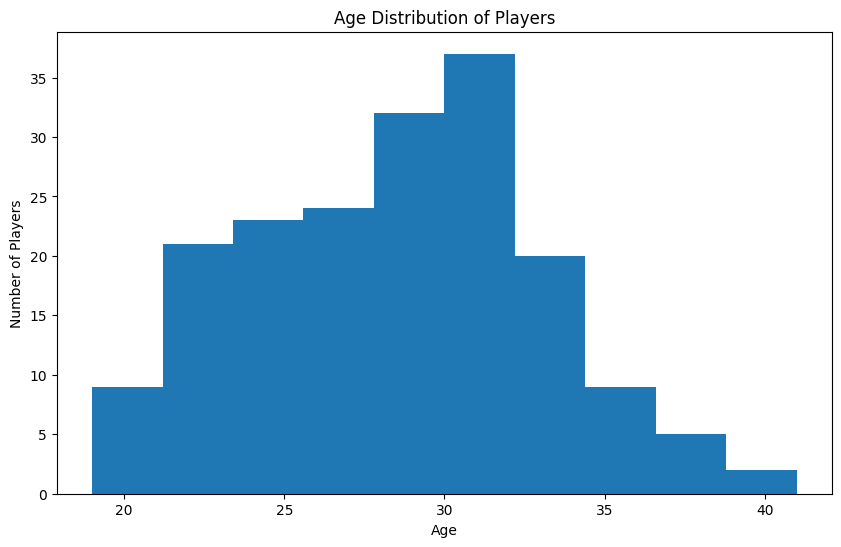

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(df["AGE"], bins=10)

plt.title("Age Distribution of Players")
plt.xlabel("Age")
plt.ylabel("Number of Players")

plt.show()

In [ ]:
print(df["AGE"].describe())

count    182.000000
mean      28.472527
std        4.541620
min       19.000000
25%       25.000000
50%       29.000000
75%       32.000000
max       41.000000
Name: AGE, dtype: float64


In [ ]:
participation_cols = [
    "MAT",
    "INNS",
    "RUNS",
    "BF"
]

display(df[participation_cols].describe())

,MAT,INNS,RUNS,BF
count,182.000000,182.000000,182.000000,182.000000
mean,49.043956,32.131868,727.000000,549.258242
std,54.257400,49.637851,1309.906783,996.531701
min,1.000000,0.000000,0.000000,0.000000
25%,9.000000,0.000000,0.000000,0.000000
50%,29.000000,9.000000,99.000000,82.000000
75%,75.000000,42.750000,736.250000,562.000000
max,234.000000,222.000000,6624.000000,5129.000000


In [ ]:
participation_cols = [
    "MAT",
    "INNS",
    "RUNS",
    "BF"
]

display(df[participation_cols].describe())

,MAT,INNS,RUNS,BF
count,182.000000,182.000000,182.000000,182.000000
mean,49.043956,32.131868,727.000000,549.258242
std,54.257400,49.637851,1309.906783,996.531701
min,1.000000,0.000000,0.000000,0.000000
25%,9.000000,0.000000,0.000000,0.000000
50%,29.000000,9.000000,99.000000,82.000000
75%,75.000000,42.750000,736.250000,562.000000
max,234.000000,222.000000,6624.000000,5129.000000


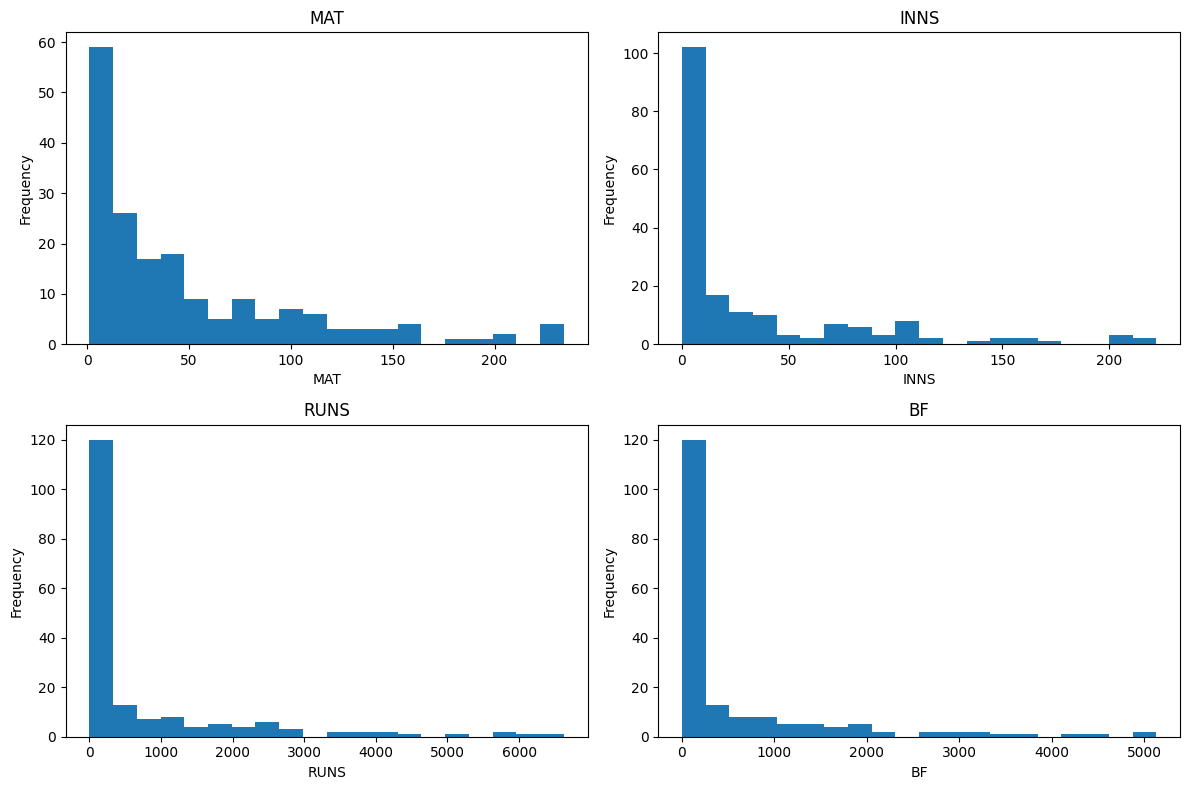

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), participation_cols):
    ax.hist(df[col], bins=20)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

Batting columns found:
['RUNS', 'HS', 'AVG', 'SR', '4S', '6S', '50S', '100S']


,RUNS,HS,AVG,SR,4S,6S,50S,100S
count,182.000000,182.000000,182.000000,182.000000,182.000000,182.000000,182.000000,182.000000
mean,727.000000,40.708791,15.025714,86.848187,64.670330,28.912088,4.164835,0.219780
std,1309.906783,40.355435,13.300330,65.808415,122.027536,49.438203,8.993876,0.776765
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,99.000000,28.500000,14.390000,114.945000,6.500000,3.500000,0.000000,0.000000
75%,736.250000,73.750000,25.472500,133.160000,61.250000,36.750000,3.000000,0.000000
max,6624.000000,140.000000,48.010000,400.000000,701.000000,240.000000,55.000000,5.000000


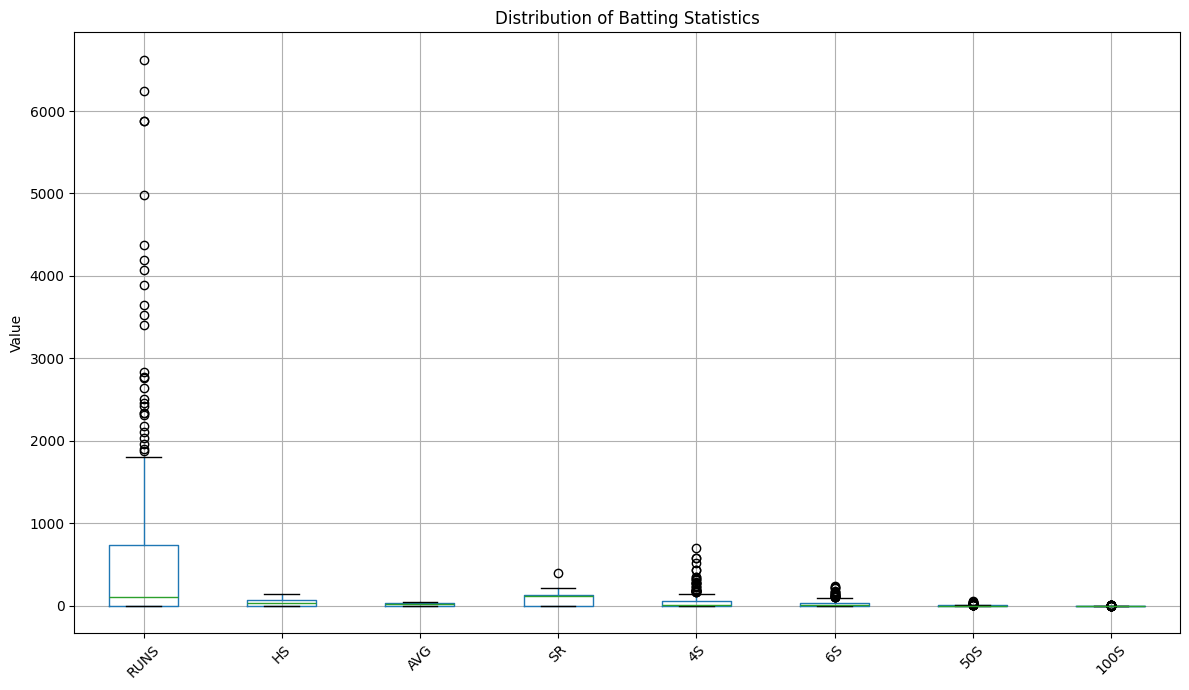

In [ ]:
# ============================================
# BATTING STATISTICS
# ============================================

batting_cols = [
    "RUNS",
    "HS",
    "AVG",
    "SR",
    "4S",
    "6S",
    "50S",
    "100S"
]

# Check that all columns exist
print("Batting columns found:")
print(batting_cols)

# Summary statistics
display(df[batting_cols].describe())

# Boxplot
plt.figure(figsize=(12, 7))

df[batting_cols].boxplot()

plt.title("Distribution of Batting Statistics")
plt.ylabel("Value")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

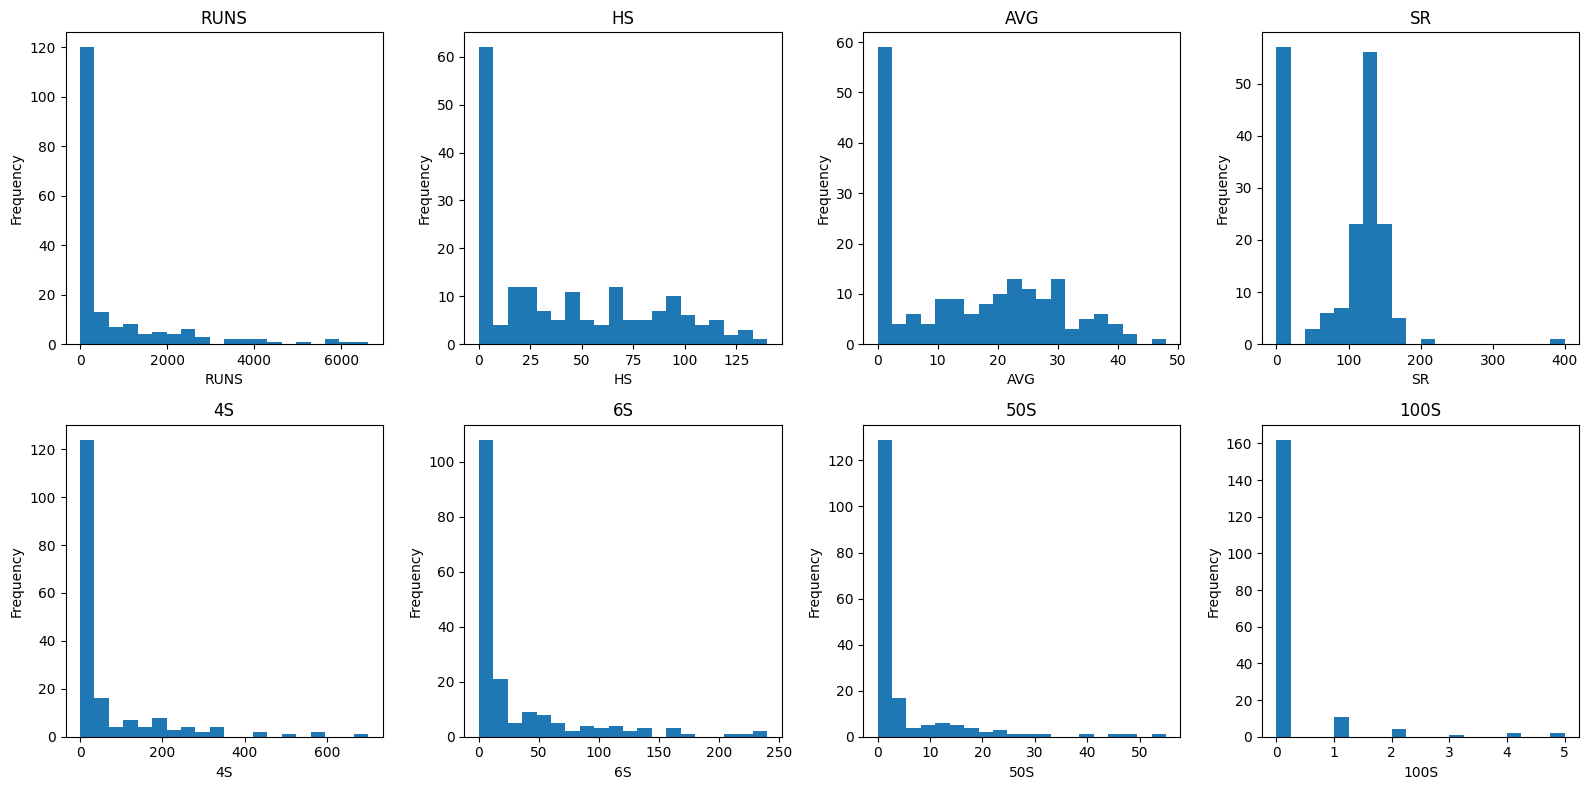

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, col in zip(axes.flatten(), batting_cols):
    ax.hist(df[col], bins=20)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# EDA SETUP
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

categorical_cols = [
    "Player",
    "Country",
    "Team"
]

derived_cols = [
    "PCA1", "PCA2", "PCA3",
    "UMAP1", "UMAP2", "UMAP3"
]

constant_cols = [
    col for col in df.columns
    if df[col].nunique() <= 1
]

exclude_cols = (
    categorical_cols
    + derived_cols
    + constant_cols
)

feature_cols = [
    col for col in df.columns
    if col not in exclude_cols
]

batting_cols = [
    "RUNS",
    "HS",
    "AVG",
    "SR",
    "4S",
    "6S",
    "50S",
    "100S"
]

bowling_cols = [
    "B_INNS",
    "B_BALLS",
    "B_RUNS",
    "B_MAIDENS",
    "B_WKTS",
    "B_AVG",
    "B_ECON",
    "B_SR",
    "B_4W",
    "B_5W"
]

print("Setup complete.")
print("ML feature count:", len(feature_cols))

Setup complete.
ML feature count: 48


In [ ]:
# ============================================
# CHECK ML FEATURES
# ============================================

print("Number of ML features:", len(feature_cols))

for i, col in enumerate(feature_cols, start=1):
    print(f"{i:2}. {col}")

Number of ML features: 48
 1. AGE
 2. CAPTAINCY EXP
 3. MAT
 4. INNS
 5. RUNS
 6. BF
 7. HS
 8. AVG
 9. SR
10. NO
11. 4S
12. 6S
13. 0S
14. 50S
15. 100S
16. TMAT
17. TINNS
18. TRUNS
19. TBF
20. THS
21. TAVG
22. TSR
23. TNO
24. T4S
25. T6S
26. T0S
27. T50S
28. T100S
29. B_INNS
30. B_BALLS
31. B_RUNS
32. B_MAIDENS
33. B_WKTS
34. B_AVG
35. B_ECON
36. B_SR
37. B_4W
38. B_5W
39. B_TINNS
40. B_TBALLS
41. B_TRUNS
42. B_TMAIDENS
43. B_TWKTS
44. B_TAVG
45. B_TECON
46. B_TSR
47. B_T4W
48. B_T5W


In [ ]:
# ============================================
# NUMERICAL SUMMARY
# ============================================

summary = df[feature_cols].describe().T

summary["missing"] = df[feature_cols].isnull().sum()
summary["unique"] = df[feature_cols].nunique()

display(summary)

,count,mean,std,min,25%,50%,75%,max,missing,unique
AGE,182.0,28.472527,4.541620,19.0,25.0,29.000,32.0000,41.00,0,22
CAPTAINCY EXP,182.0,0.362637,1.614961,0.0,0.0,0.000,0.0000,15.00,0,8
MAT,182.0,49.043956,54.257400,1.0,9.0,29.000,75.0000,234.00,0,88
INNS,182.0,32.131868,49.637851,0.0,0.0,9.000,42.7500,222.00,0,72
RUNS,182.0,727.000000,1309.906783,0.0,0.0,99.000,736.2500,6624.00,0,118
BF,182.0,549.258242,996.531701,0.0,0.0,82.000,562.0000,5129.00,0,119
HS,182.0,40.708791,40.355435,0.0,0.0,28.500,73.7500,140.00,0,80
AVG,182.0,15.025714,13.300330,0.0,0.0,14.390,25.4725,48.01,0,120
SR,182.0,86.848187,65.808415,0.0,0.0,114.945,133.1600,400.00,0,122
NO,182.0,7.024725,15.002051,0.0,0.0,1.000,7.7500,137.50,0,36


In [ ]:
# ============================================
# ZERO VALUE ANALYSIS
# ============================================

zero_counts = (df[feature_cols] == 0).sum()

zero_percentage = (
    zero_counts / len(df) * 100
)

zero_analysis = pd.DataFrame({
    "Zero Count": zero_counts,
    "Zero Percentage": zero_percentage
}).sort_values(
    "Zero Percentage",
    ascending=False
)

display(zero_analysis)

,Zero Count,Zero Percentage
B_T5W,173,95.054945
T100S,168,92.307692
B_5W,168,92.307692
CAPTAINCY EXP,163,89.560440
100S,162,89.010989
B_T4W,147,80.769231
B_TMAIDENS,145,79.670330
B_4W,141,77.472527
T50S,133,73.076923
B_MAIDENS,132,72.527473


In [ ]:
# ============================================
# SKEWNESS ANALYSIS
# ============================================

skewness = (
    df[feature_cols]
    .skew()
    .sort_values(ascending=False)
)

skew_df = pd.DataFrame({
    "Skewness": skewness
})

display(skew_df)

,Skewness
B_TECON,13.489682
B_ECON,13.385988
CAPTAINCY EXP,6.532914
B_T5W,5.102986
B_TMAIDENS,5.064346
NO,5.003538
T100S,4.859234
100S,4.458568
T50S,4.002853
B_4W,3.984801


In [ ]:
high_skew = skew_df[
    skew_df["Skewness"].abs() > 1
]

print(
    "Features with |skewness| > 1:",
    len(high_skew)
)

display(high_skew)

Features with |skewness| > 1: 40


,Skewness
B_TECON,13.489682
B_ECON,13.385988
CAPTAINCY EXP,6.532914
B_T5W,5.102986
B_TMAIDENS,5.064346
NO,5.003538
T100S,4.859234
100S,4.458568
T50S,4.002853
B_4W,3.984801


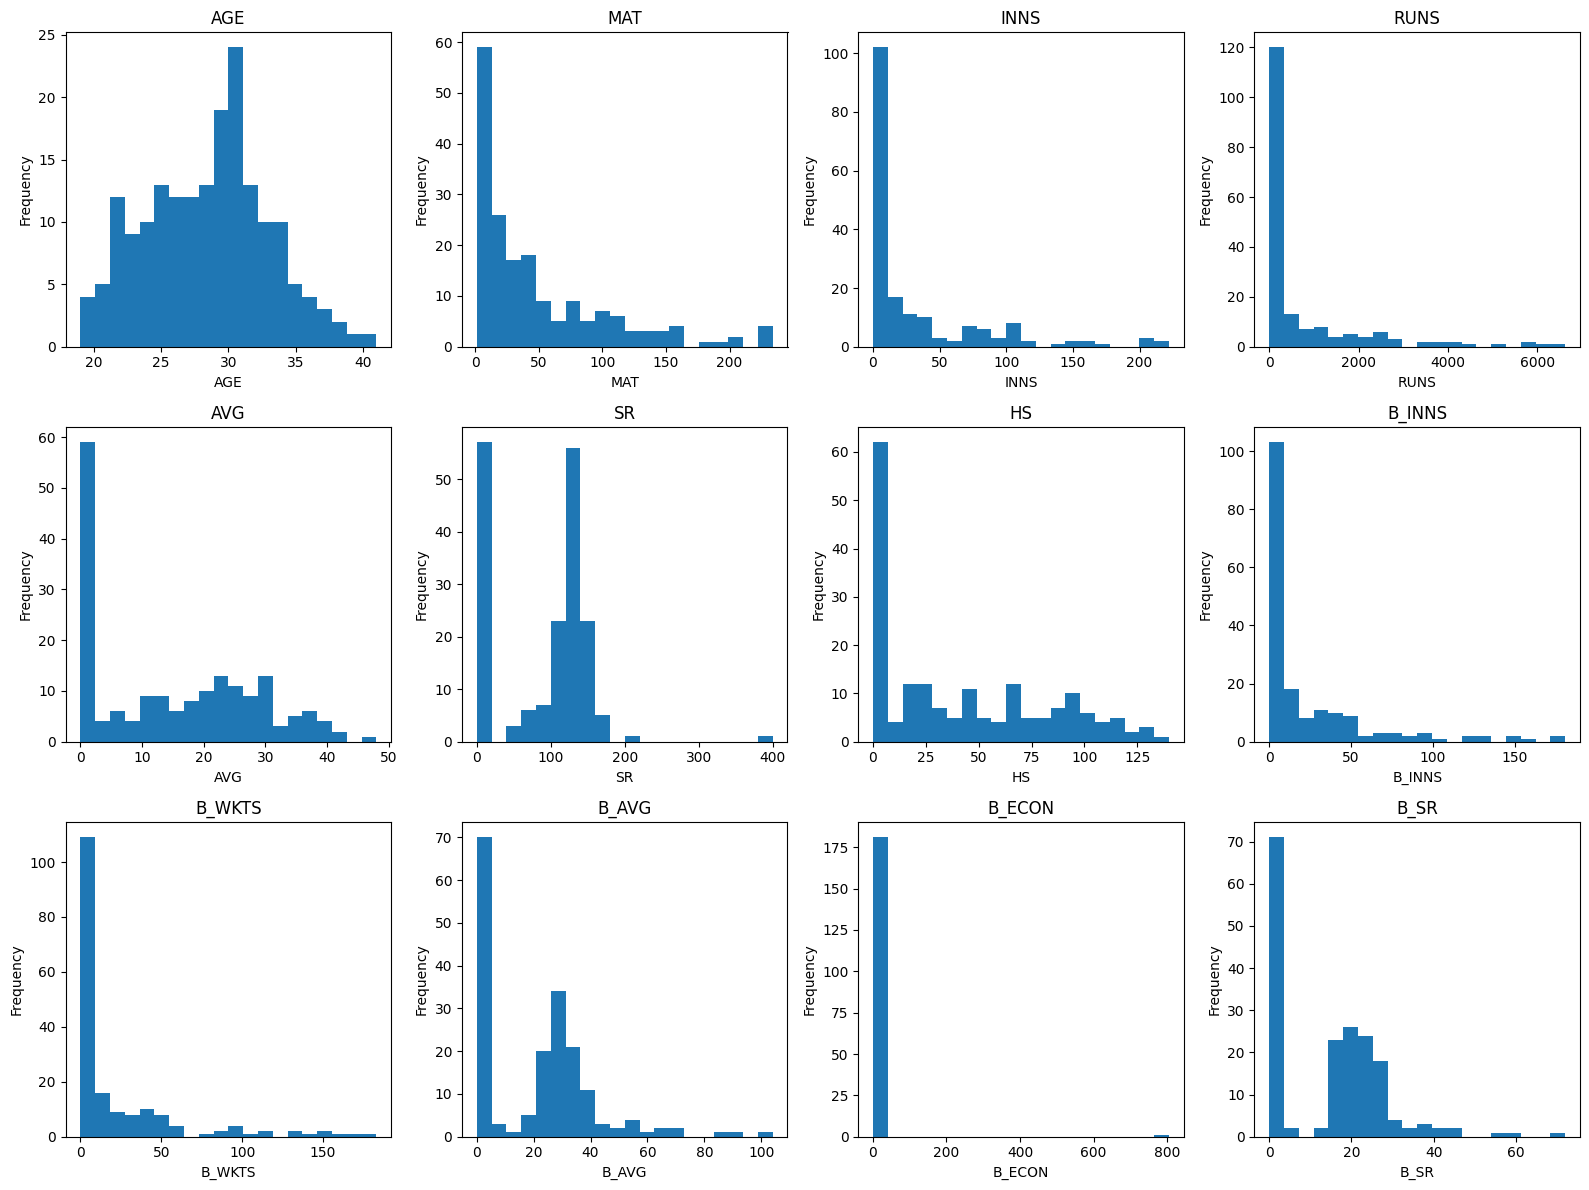

In [ ]:
# ============================================
# IMPORTANT PERFORMANCE DISTRIBUTIONS
# ============================================

important_cols = [
    "AGE",
    "MAT",
    "INNS",
    "RUNS",
    "AVG",
    "SR",
    "HS",
    "B_INNS",
    "B_WKTS",
    "B_AVG",
    "B_ECON",
    "B_SR"
]

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for ax, col in zip(axes.flatten(), important_cols):
    ax.hist(df[col], bins=20)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

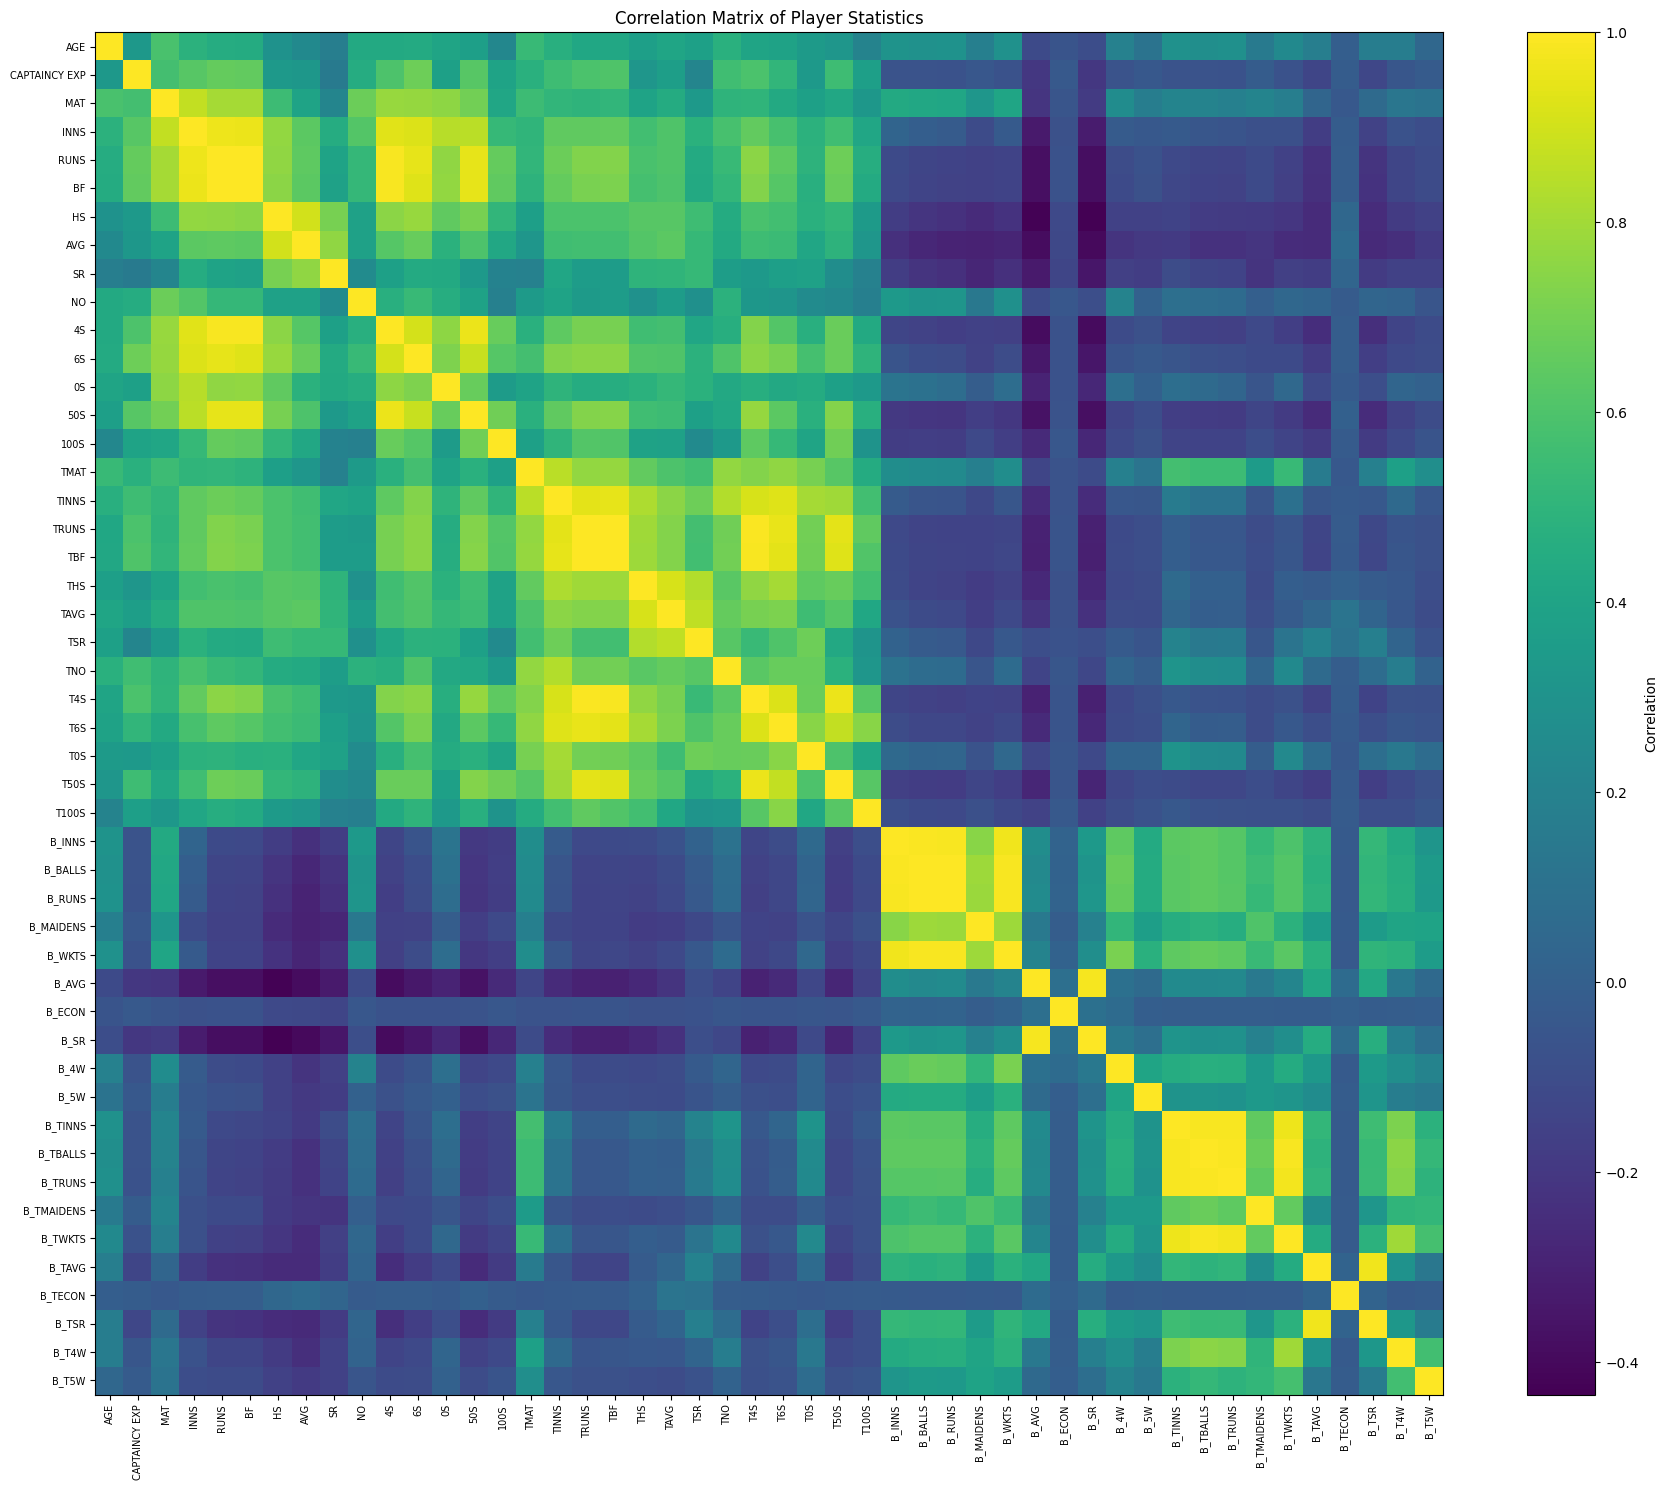

In [ ]:
# ============================================
# CORRELATION MATRIX
# ============================================

corr = df[feature_cols].corr()

plt.figure(figsize=(18, 15))

plt.imshow(corr, aspect="auto")

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(feature_cols)),
    feature_cols,
    rotation=90,
    fontsize=7
)

plt.yticks(
    range(len(feature_cols)),
    feature_cols,
    fontsize=7
)

plt.title("Correlation Matrix of Player Statistics")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# TOP CORRELATION PAIRS
# ============================================

corr_matrix = df[feature_cols].corr()

upper = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

correlation_pairs = (
    upper
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

correlation_pairs["Absolute Correlation"] = (
    correlation_pairs["Correlation"].abs()
)

correlation_pairs = correlation_pairs.sort_values(
    "Absolute Correlation",
    ascending=False
)

display(
    correlation_pairs.head(20)
)

,Feature 1,Feature 2,Correlation,Absolute Correlation
182,RUNS,BF,0.997713,0.997713
663,TRUNS,TBF,0.996871,0.996871
957,B_BALLS,B_RUNS,0.994732,0.994732
1092,B_TBALLS,B_TRUNS,0.993004,0.993004
938,B_INNS,B_BALLS,0.989847,0.989847
668,TRUNS,T4S,0.989357,0.989357
939,B_INNS,B_RUNS,0.988716,0.988716
1083,B_TINNS,B_TBALLS,0.988502,0.988502
229,BF,4S,0.988119,0.988119
187,RUNS,4S,0.987624,0.987624


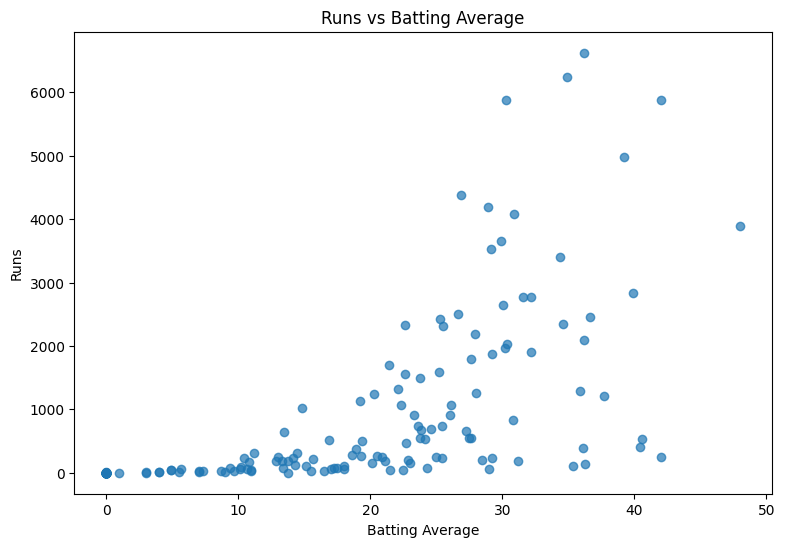

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["AVG"],
    df["RUNS"],
    alpha=0.7
)

plt.xlabel("Batting Average")
plt.ylabel("Runs")
plt.title("Runs vs Batting Average")

plt.show()

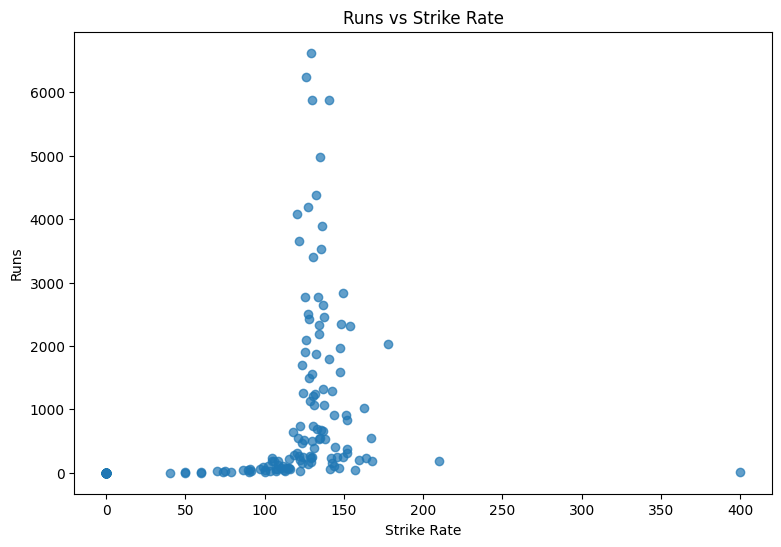

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["SR"],
    df["RUNS"],
    alpha=0.7
)

plt.xlabel("Strike Rate")
plt.ylabel("Runs")
plt.title("Runs vs Strike Rate")

plt.show()

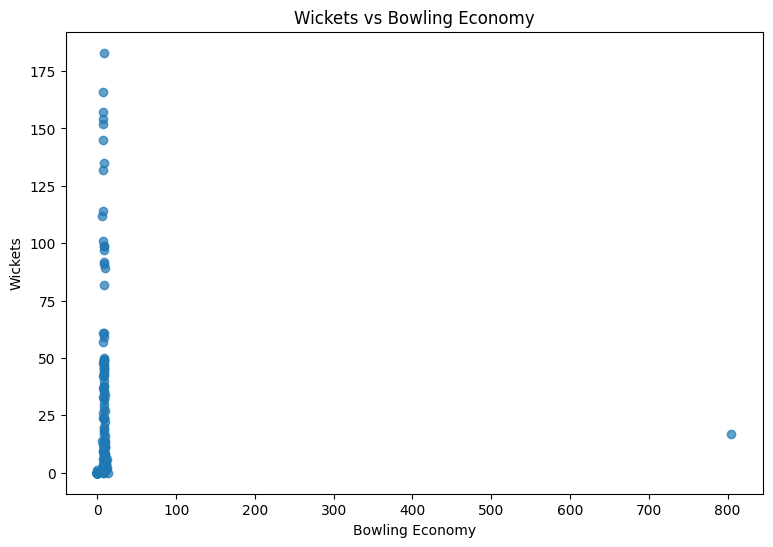

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["B_ECON"],
    df["B_WKTS"],
    alpha=0.7
)

plt.xlabel("Bowling Economy")
plt.ylabel("Wickets")
plt.title("Wickets vs Bowling Economy")

plt.show()

In [ ]:
top_runs = (
    df[["Player", "Country", "Team", "RUNS", "AVG", "SR"]]
    .sort_values("RUNS", ascending=False)
    .head(10)
)

display(top_runs)

,Player,Country,Team,RUNS,AVG,SR
131,Virat Kohli,IND,RCB,6624.0,36.20,129.15
111,Shikhar Dhawan,IND,PK,6243.0,34.88,126.33
18,David Warner,AUS,DC,5881.0,42.01,140.69
93,Rohit Sharma,IND,MI,5879.0,30.30,129.89
5,MS Dhoni,IND,CSK,4978.0,39.20,135.20
133,Dinesh Karthik,IND,RCB,4376.0,26.85,132.65
2,Ambati Rayudu,IND,CSK,4190.0,28.90,127.12
59,Ajinkya Rahane,IND,KKR,4074.0,30.86,120.68
73,K L Rahul,IND,LSG,3889.0,48.01,136.22
79,Manish Pandey,IND,LSG,3648.0,29.90,121.52


In [ ]:
# ============================================
# OUTLIER ANALYSIS USING IQR
# ============================================

outlier_results = []

for col in feature_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    )

    outlier_results.append({
        "Feature": col,
        "Outlier Count": outliers.sum(),
        "Outlier %": round(
            outliers.mean() * 100,
            2
        )
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df = outlier_df.sort_values(
    "Outlier Count",
    ascending=False
)

display(outlier_df.head(20))

,Feature,Outlier Count,Outlier %
36,B_4W,41,22.53
41,B_TMAIDENS,37,20.33
46,B_T4W,35,19.23
13,50S,33,18.13
26,T50S,33,18.13
10,4S,30,16.48
23,T4S,30,16.48
42,B_TWKTS,29,15.93
4,RUNS,28,15.38
39,B_TBALLS,26,14.29


In [ ]:
# ============================================
# STEP 11 — HIGHLY CORRELATED FEATURE PAIRS
# ============================================

# Show correlations >= 0.90
high_corr_pairs = correlation_pairs[
    correlation_pairs["Absolute Correlation"] >= 0.90
].copy()

print(
    "Number of feature pairs with |correlation| >= 0.90:",
    len(high_corr_pairs)
)

display(high_corr_pairs)

Number of feature pairs with |correlation| >= 0.90: 42


,Feature 1,Feature 2,Correlation,Absolute Correlation
182,RUNS,BF,0.997713,0.997713
663,TRUNS,TBF,0.996871,0.996871
957,B_BALLS,B_RUNS,0.994732,0.994732
1092,B_TBALLS,B_TRUNS,0.993004,0.993004
938,B_INNS,B_BALLS,0.989847,0.989847
668,TRUNS,T4S,0.989357,0.989357
939,B_INNS,B_RUNS,0.988716,0.988716
1083,B_TINNS,B_TBALLS,0.988502,0.988502
229,BF,4S,0.988119,0.988119
187,RUNS,4S,0.987624,0.987624


In [ ]:
# ============================================
# STEP 12 — VERY HIGH CORRELATION
# ============================================

very_high_corr_pairs = correlation_pairs[
    correlation_pairs["Absolute Correlation"] >= 0.95
].copy()

print(
    "Number of feature pairs with |correlation| >= 0.95:",
    len(very_high_corr_pairs)
)

display(very_high_corr_pairs)

Number of feature pairs with |correlation| >= 0.95: 25


,Feature 1,Feature 2,Correlation,Absolute Correlation
182,RUNS,BF,0.997713,0.997713
663,TRUNS,TBF,0.996871,0.996871
957,B_BALLS,B_RUNS,0.994732,0.994732
1092,B_TBALLS,B_TRUNS,0.993004,0.993004
938,B_INNS,B_BALLS,0.989847,0.989847
668,TRUNS,T4S,0.989357,0.989357
939,B_INNS,B_RUNS,0.988716,0.988716
1083,B_TINNS,B_TBALLS,0.988502,0.988502
229,BF,4S,0.988119,0.988119
187,RUNS,4S,0.987624,0.987624


In [ ]:
# ============================================
# STEP 13 — FINAL FEATURE REVIEW
# ============================================

print("Total ML features:", len(feature_cols))
print("\nFeature list:\n")

for i, col in enumerate(feature_cols, 1):
    print(f"{i:2}. {col}")

Total ML features: 48

Feature list:

 1. AGE
 2. CAPTAINCY EXP
 3. MAT
 4. INNS
 5. RUNS
 6. BF
 7. HS
 8. AVG
 9. SR
10. NO
11. 4S
12. 6S
13. 0S
14. 50S
15. 100S
16. TMAT
17. TINNS
18. TRUNS
19. TBF
20. THS
21. TAVG
22. TSR
23. TNO
24. T4S
25. T6S
26. T0S
27. T50S
28. T100S
29. B_INNS
30. B_BALLS
31. B_RUNS
32. B_MAIDENS
33. B_WKTS
34. B_AVG
35. B_ECON
36. B_SR
37. B_4W
38. B_5W
39. B_TINNS
40. B_TBALLS
41. B_TRUNS
42. B_TMAIDENS
43. B_TWKTS
44. B_TAVG
45. B_TECON
46. B_TSR
47. B_T4W
48. B_T5W


In [ ]:
# ============================================
# STEP 14 — FEATURE GROUP SUMMARY
# ============================================

groups = {
    "Experience": [
        "AGE",
        "CAPTAINCY EXP"
    ],

    "Batting": [
        "MAT", "INNS", "RUNS", "BF", "HS",
        "AVG", "SR", "NO", "4S", "6S",
        "0S", "50S", "100S"
    ],

    "Career Batting": [
        "TMAT", "TINNS", "TRUNS", "TBF", "THS",
        "TAVG", "TSR", "TNO", "T4S", "T6S",
        "T0S", "T50S", "T100S"
    ],

    "Bowling": [
        "B_INNS", "B_BALLS", "B_RUNS", "B_MAIDENS",
        "B_WKTS", "B_AVG", "B_ECON", "B_SR",
        "B_4W", "B_5W"
    ],

    "Career Bowling": [
        "B_TINNS", "B_TBALLS", "B_TRUNS", "B_TMAIDENS",
        "B_TWKTS", "B_TAVG", "B_TECON", "B_TSR",
        "B_T4W", "B_T5W"
    ]
}

for group_name, cols in groups.items():
    available = [c for c in cols if c in feature_cols]
    print(f"{group_name}: {len(available)} features")
    print(available)
    print()

Experience: 2 features
['AGE', 'CAPTAINCY EXP']

Batting: 13 features
['MAT', 'INNS', 'RUNS', 'BF', 'HS', 'AVG', 'SR', 'NO', '4S', '6S', '0S', '50S', '100S']

Career Batting: 13 features
['TMAT', 'TINNS', 'TRUNS', 'TBF', 'THS', 'TAVG', 'TSR', 'TNO', 'T4S', 'T6S', 'T0S', 'T50S', 'T100S']

Bowling: 10 features
['B_INNS', 'B_BALLS', 'B_RUNS', 'B_MAIDENS', 'B_WKTS', 'B_AVG', 'B_ECON', 'B_SR', 'B_4W', 'B_5W']

Career Bowling: 10 features
['B_TINNS', 'B_TBALLS', 'B_TRUNS', 'B_TMAIDENS', 'B_TWKTS', 'B_TAVG', 'B_TECON', 'B_TSR', 'B_T4W', 'B_T5W']



In [ ]:
# ============================================
# STEP 15 — FINAL FEATURE SELECTION
# ============================================

final_features = [
    # Experience
    "AGE",
    "CAPTAINCY EXP",

    # Batting
    "MAT",
    "INNS",
    "RUNS",
    "HS",
    "AVG",
    "SR",
    "NO",
    "4S",
    "6S",
    "50S",
    "100S",
    "0S",

    # Career batting
    "TMAT",
    "TINNS",
    "TRUNS",
    "THS",
    "TAVG",
    "TSR",
    "TNO",
    "T4S",
    "T6S",
    "T50S",
    "T100S",

    # Bowling
    "B_INNS",
    "B_BALLS",
    "B_WKTS",
    "B_MAIDENS",
    "B_AVG",
    "B_ECON",
    "B_SR",

    # Career bowling
    "B_TINNS",
    "B_TBALLS",
    "B_TWKTS",
    "B_TMAIDENS",
    "B_TAVG",
    "B_TECON",
    "B_TSR",
    "B_T4W",
    "B_T5W"
]

print("Final feature count:", len(final_features))

print("\nFinal features:")
for i, col in enumerate(final_features, 1):
    print(f"{i:2}. {col}")

Final feature count: 41

Final features:
 1. AGE
 2. CAPTAINCY EXP
 3. MAT
 4. INNS
 5. RUNS
 6. HS
 7. AVG
 8. SR
 9. NO
10. 4S
11. 6S
12. 50S
13. 100S
14. 0S
15. TMAT
16. TINNS
17. TRUNS
18. THS
19. TAVG
20. TSR
21. TNO
22. T4S
23. T6S
24. T50S
25. T100S
26. B_INNS
27. B_BALLS
28. B_WKTS
29. B_MAIDENS
30. B_AVG
31. B_ECON
32. B_SR
33. B_TINNS
34. B_TBALLS
35. B_TWKTS
36. B_TMAIDENS
37. B_TAVG
38. B_TECON
39. B_TSR
40. B_T4W
41. B_T5W


In [ ]:
# ============================================
# STEP 16 — VERIFY FINAL FEATURES
# ============================================

missing_features = [
    col for col in final_features
    if col not in df.columns
]

if missing_features:
    print("Missing features:", missing_features)
else:
    print("✓ All 41 features exist in the dataset.")

X = df[final_features].copy()

print("Feature matrix shape:", X.shape)
print("Missing values:", X.isnull().sum().sum())

✓ All 41 features exist in the dataset.
Feature matrix shape: (182, 41)
Missing values: 0


In [ ]:
# ============================================
# STEP 17 — FINAL FEATURE SKEWNESS
# ============================================

skewness = X.skew().sort_values(ascending=False)

skewness_df = pd.DataFrame({
    "Feature": skewness.index,
    "Skewness": skewness.values,
    "Absolute Skewness": skewness.abs().values
})

display(skewness_df)

print(
    "Features with |skewness| > 1:",
    (skewness.abs() > 1).sum()
)

,Feature,Skewness,Absolute Skewness
0,B_TECON,13.489682,13.489682
1,B_ECON,13.385988,13.385988
2,CAPTAINCY EXP,6.532914,6.532914
3,B_T5W,5.102986,5.102986
4,B_TMAIDENS,5.064346,5.064346
5,NO,5.003538,5.003538
6,T100S,4.859234,4.859234
7,100S,4.458568,4.458568
8,T50S,4.002853,4.002853
9,B_MAIDENS,3.846120,3.846120


Features with |skewness| > 1: 33


In [ ]:
# ============================================
# STEP 18 — HIGHLY SKEWED FEATURES
# ============================================

high_skew_features = skewness_df[
    skewness_df["Absolute Skewness"] > 1
]

display(high_skew_features)

,Feature,Skewness,Absolute Skewness
0,B_TECON,13.489682,13.489682
1,B_ECON,13.385988,13.385988
2,CAPTAINCY EXP,6.532914,6.532914
3,B_T5W,5.102986,5.102986
4,B_TMAIDENS,5.064346,5.064346
5,NO,5.003538,5.003538
6,T100S,4.859234,4.859234
7,100S,4.458568,4.458568
8,T50S,4.002853,4.002853
9,B_MAIDENS,3.846120,3.846120


In [ ]:
# ============================================
# STEP 19 — PREPROCESSING SETUP
# ============================================

from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

print("RobustScaler created.")
print("Input feature count:", len(final_features))

RobustScaler created.
Input feature count: 41


In [ ]:
# ============================================
# STEP 20 — FIT SCALER
# ============================================

X_scaled = scaler.fit_transform(X)

print("Original shape:", X.shape)
print("Scaled shape:", X_scaled.shape)
print("Scaler fitted successfully.")

Original shape: (182, 41)
Scaled shape: (182, 41)
Scaler fitted successfully.


In [ ]:
# ============================================
# STEP 21 — CHECK SCALED DATA
# ============================================

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=final_features
)

display(X_scaled_df.describe().T)

,count,mean,std,min,25%,50%,75%,max
AGE,182.0,-0.075353,0.648803,-1.428571,-0.571429,0.000000e+00,0.428571,1.714286
CAPTAINCY EXP,182.0,0.362637,1.614961,0.000000,0.000000,0.000000e+00,0.000000,15.000000
MAT,182.0,0.303696,0.822082,-0.424242,-0.303030,0.000000e+00,0.696970,3.106061
INNS,182.0,0.541096,1.161119,-0.210526,-0.210526,0.000000e+00,0.789474,4.982456
RUNS,182.0,0.852971,1.779160,-0.134465,-0.134465,0.000000e+00,0.865535,8.862479
HS,182.0,0.165543,0.547192,-0.386441,-0.386441,0.000000e+00,0.613559,1.511864
AVG,182.0,0.024957,0.522145,-0.564923,-0.564923,-3.469447e-17,0.435077,1.319855
SR,182.0,-0.211000,0.494206,-0.863210,-0.863210,5.334275e-17,0.136790,2.140695
NO,182.0,0.777384,1.935749,-0.129032,-0.129032,0.000000e+00,0.870968,17.612903
4S,182.0,0.949720,1.992286,-0.106122,-0.106122,0.000000e+00,0.893878,11.338776


In [ ]:
# ============================================
# STEP 22 — VALIDATE PREPROCESSING
# ============================================

print("NaN values:", np.isnan(X_scaled).sum())
print("Infinite values:", np.isinf(X_scaled).sum())
print("Shape:", X_scaled.shape)

NaN values: 0
Infinite values: 0
Shape: (182, 41)


In [ ]:
# ============================================
# STEP 23 — PCA WITH ALL COMPONENTS
# ============================================

from sklearn.decomposition import PCA

pca_full = PCA()

X_pca_full = pca_full.fit_transform(X_scaled)

print("Original feature count:", X_scaled.shape[1])
print("PCA components:", pca_full.n_components_)
print("Transformed shape:", X_pca_full.shape)

Original feature count: 41
PCA components: 41
Transformed shape: (182, 41)


In [ ]:
# ============================================
# STEP 24 — EXPLAINED VARIANCE
# ============================================

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

pca_variance_df = pd.DataFrame({
    "Component": np.arange(1, len(explained_variance) + 1),
    "Explained Variance": explained_variance,
    "Cumulative Variance": cumulative_variance
})

display(pca_variance_df)

,Component,Explained Variance,Cumulative Variance
0,1,9.749931e-01,0.974993
1,2,1.025182e-02,0.985245
2,3,8.259747e-03,0.993505
3,4,2.320733e-03,0.995825
4,5,1.506423e-03,0.997332
5,6,5.875331e-04,0.997919
6,7,5.731763e-04,0.998493
7,8,2.984130e-04,0.998791
8,9,2.001823e-04,0.998991
9,10,1.665939e-04,0.999158


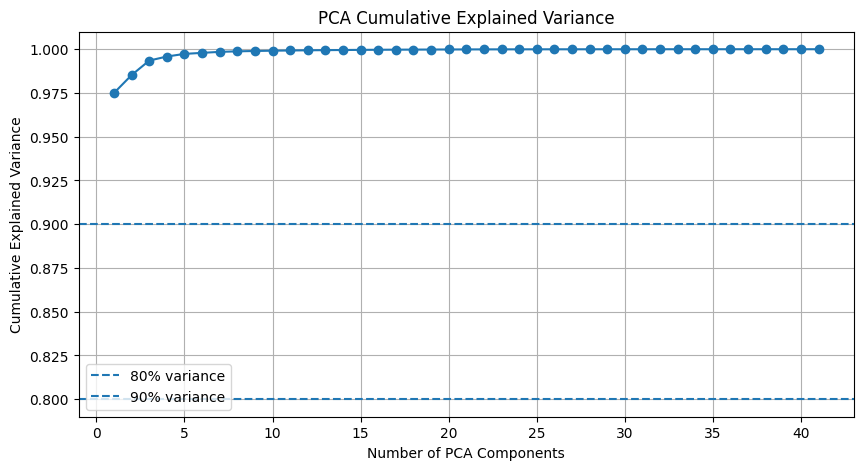

In [ ]:
# ============================================
# STEP 25 — PCA VARIANCE PLOT
# ============================================

plt.figure(figsize=(10, 5))

plt.plot(
    pca_variance_df["Component"],
    pca_variance_df["Cumulative Variance"],
    marker="o"
)

plt.axhline(
    0.80,
    linestyle="--",
    label="80% variance"
)

plt.axhline(
    0.90,
    linestyle="--",
    label="90% variance"
)

plt.xlabel("Number of PCA Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
# ============================================
# STEP 27 — FINAL PCA MODEL
# ============================================

pca = PCA(n_components=3)

X_pca = pca.fit_transform(X_scaled)

print("PCA shape:", X_pca.shape)

print("\nExplained variance:")
for i, variance in enumerate(pca.explained_variance_ratio_, 1):
    print(f"PCA{i}: {variance:.4%}")

print(
    "\nTotal variance explained by 3 components:",
    f"{pca.explained_variance_ratio_.sum():.4%}"
)

PCA shape: (182, 3)

Explained variance:
PCA1: 97.4993%
PCA2: 1.0252%
PCA3: 0.8260%

Total variance explained by 3 components: 99.3505%


In [ ]:
# ============================================
# STEP 28 — PCA COORDINATES
# ============================================

pca_df = pd.DataFrame(
    X_pca,
    columns=["PCA1", "PCA2", "PCA3"]
)

pca_df["Player"] = df["Player"].values
pca_df["Country"] = df["Country"].values
pca_df["Team"] = df["Team"].values

display(pca_df.head())

,PCA1,PCA2,PCA3,Player,Country,Team
0,-5.877644,0.573682,-1.011150,Ruturaj Gaikwad,IND,CSK
1,-4.633525,-1.292223,-0.499248,Shivam Dube,IND,CSK
2,-5.883469,4.255218,0.126358,Ambati Rayudu,IND,CSK
3,-5.897249,6.508207,1.208983,Devon Conway,NZ,CSK
4,-4.875472,5.729601,1.632094,Moeen Ali,ENG,CSK


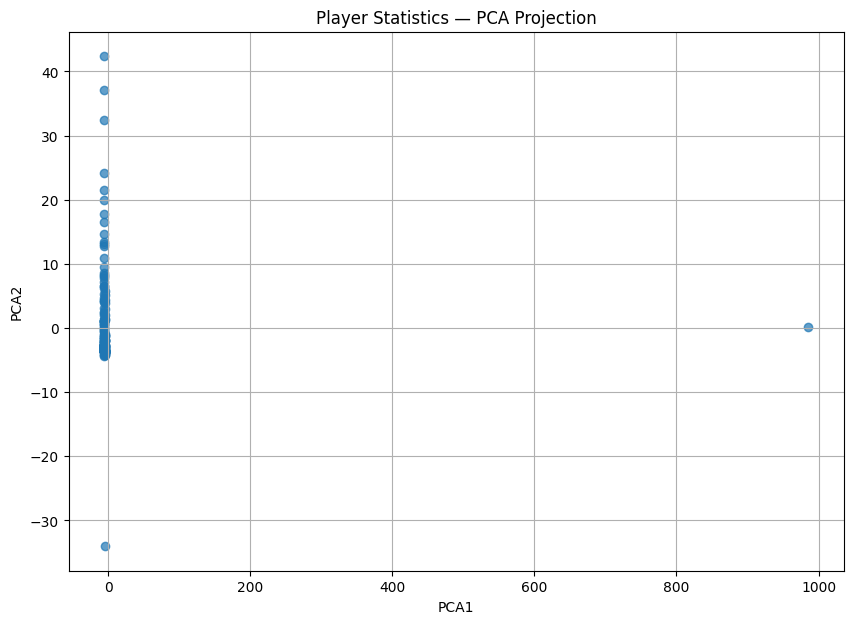

In [ ]:
# ============================================
# STEP 29 — PCA 2D VISUALIZATION
# ============================================

plt.figure(figsize=(10, 7))

plt.scatter(
    pca_df["PCA1"],
    pca_df["PCA2"],
    alpha=0.7
)

plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.title("Player Statistics — PCA Projection")
plt.grid(True)
plt.show()

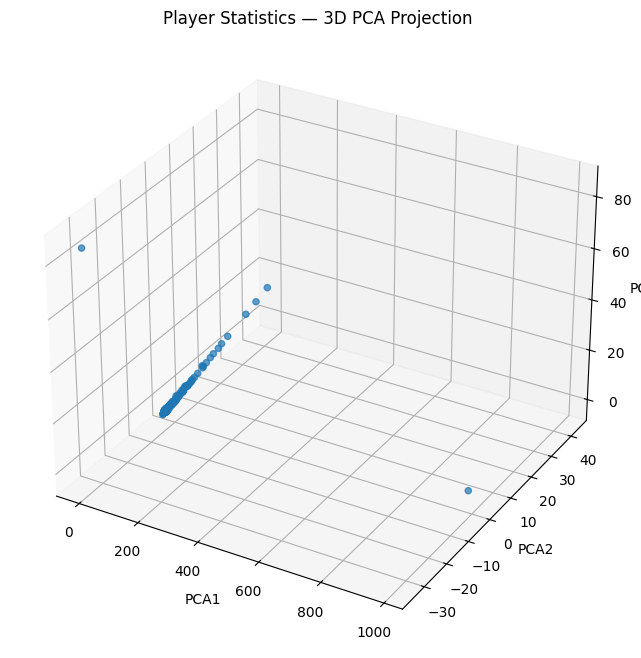

In [ ]:
# ============================================
# STEP 30 — PCA 3D VISUALIZATION
# ============================================

from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(11, 8))

ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    pca_df["PCA1"],
    pca_df["PCA2"],
    pca_df["PCA3"],
    alpha=0.7
)

ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")

ax.set_title(
    "Player Statistics — 3D PCA Projection"
)

plt.show()

In [ ]:
# ============================================
# STEP 31 — PCA LOADINGS
# ============================================

loadings = pd.DataFrame(
    pca.components_.T,
    columns=["PCA1", "PCA2", "PCA3"],
    index=final_features
)

# Absolute PCA1 contribution
pca1_loadings = loadings["PCA1"].abs().sort_values(
    ascending=False
)

print("Top features contributing to PCA1:")
display(pca1_loadings.head(15))

Top features contributing to PCA1:


,PCA1
B_TECON,0.999994
T50S,0.002053
TAVG,0.001027
TSR,0.000807
NO,0.000657
T4S,0.000625
T6S,0.000624
B_TBALLS,0.000623
TRUNS,0.000619
B_AVG,0.000591


In [ ]:
# ============================================
# STEP 32 — TOP FEATURES FOR EACH COMPONENT
# ============================================

for component in ["PCA1", "PCA2", "PCA3"]:

    print(f"\n===== {component} =====")

    component_features = (
        loadings[component]
        .abs()
        .sort_values(ascending=False)
        .head(10)
    )

    display(component_features)


===== PCA1 =====


,PCA1
B_TECON,0.999994
T50S,0.002053
TAVG,0.001027
TSR,0.000807
NO,0.000657
T4S,0.000625
T6S,0.000624
B_TBALLS,0.000623
TRUNS,0.000619
B_AVG,0.000591



===== PCA2 =====


,PCA2
T50S,0.617080
50S,0.333420
B_ECON,0.332902
T4S,0.304963
TRUNS,0.225885
4S,0.214682
T6S,0.196180
RUNS,0.194993
6S,0.144840
CAPTAINCY EXP,0.133816



===== PCA3 =====


,PCA3
B_ECON,0.942510
T50S,0.228941
50S,0.113347
T4S,0.109707
TRUNS,0.080549
4S,0.069535
T6S,0.069184
RUNS,0.063212
CAPTAINCY EXP,0.049488
6S,0.046805


In [ ]:
# ============================================
# STEP 33 — DIAGNOSE ECONOMY VARIABLES
# ============================================

econ_cols = ["B_ECON", "B_TECON"]

display(
    df[econ_cols].describe().T
)

print("\nUnique values:")
for col in econ_cols:
    print(col, "→", df[col].nunique())

print("\nIQR:")
for col in econ_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    print(col, "→", q3 - q1)

,count,mean,std,min,25%,50%,75%,max
B_ECON,182.0,9.729011,59.427424,0.0,0.0,7.635,8.6775,805.0
B_TECON,182.0,47.593187,594.085309,0.0,0.0,0.000,8.0875,8018.0



Unique values:
B_ECON → 102
B_TECON → 73

IQR:
B_ECON → 8.6775
B_TECON → 8.0875


In [ ]:
# ============================================
# STEP 34 — ECONOMY VALUE CHECK
# ============================================

for col in econ_cols:
    print(f"\n===== {col} =====")
    print("Smallest values:")
    print(df[col].nsmallest(10).values)

    print("Largest values:")
    print(df[col].nlargest(10).values)


===== B_ECON =====
Smallest values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Largest values:
[805.    13.5   12.56  11.86  11.56  11.41  10.88  10.88  10.7   10.62]

===== B_TECON =====
Smallest values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Largest values:
[8018.     16.     14.4    10.51   10.5    10.49   10.43   10.17   10.05
    9.98]


In [ ]:
# ============================================
# STEP 35 — IDENTIFY EXTREME ECONOMY RECORDS
# ============================================

display(
    df.loc[
        df["B_ECON"].nlargest(5).index,
        ["Player", "B_INNS", "B_BALLS", "B_RUNS", "B_ECON"]
    ]
)

print("\nCareer economy extremes:")

display(
    df.loc[
        df["B_TECON"].nlargest(5).index,
        ["Player", "B_TINNS", "B_TBALLS", "B_TRUNS", "B_TECON"]
    ]
)

,Player,B_INNS,B_BALLS,B_RUNS,B_ECON
110,Mayank Markande,20.0,360.0,510.0,805.00
153,Daryl Mitchell,2.0,12.0,27.0,13.50
177,Abdul Samad,5.0,54.0,113.0,12.56
119,Odean Smith,6.0,90.0,178.0,11.86
175,Sean Abbott,3.0,54.0,104.0,11.56



Career economy extremes:


,Player,B_TINNS,B_TBALLS,B_TRUNS,B_TECON
56,Venkatesh Iyer,4.0,55.0,75.0,8018.00
16,Matheesha Pathirana,1.0,6.0,16.0,16.00
7,Dwaine Pretorius,27.0,504.0,696.0,14.40
170,Romario Shepherd,20.0,371.0,650.0,10.51
121,Rishi Dhawan,1.0,24.0,42.0,10.50


In [ ]:
# ============================================
# STEP 37 — IDENTIFY ALL ECONOMY ERRORS
# ============================================

econ_tolerance = 0.01

B_ECON_errors = economy_check[
    economy_check["Difference B_ECON"] > econ_tolerance
]

B_TECON_errors = economy_check[
    economy_check["Difference B_TECON"] > econ_tolerance
]

print(
    "B_ECON discrepancies:",
    len(B_ECON_errors)
)

print(
    "B_TECON discrepancies:",
    len(B_TECON_errors)
)

print("\nB_ECON discrepancies:")
display(
    B_ECON_errors[
        [
            "Player",
            "Stored B_ECON",
            "Calculated B_ECON",
            "Difference B_ECON"
        ]
    ]
)

print("\nB_TECON discrepancies:")
display(
    B_TECON_errors[
        [
            "Player",
            "Stored B_TECON",
            "Calculated B_TECON",
            "Difference B_TECON"
        ]
    ]
)

B_ECON discrepancies: 4
B_TECON discrepancies: 6

B_ECON discrepancies:


,Player,Stored B_ECON,Calculated B_ECON,Difference B_ECON
43,Rashid Khan,6.38,7.743964,1.363964
95,Dewald Brevis,0.00,16.000000,16.000000
97,Ramandeep Singh,9.00,0.000000,9.000000
110,Mayank Markande,805.00,8.500000,796.500000



B_TECON discrepancies:


,Player,Stored B_TECON,Calculated B_TECON,Difference B_TECON
7,Dwaine Pretorius,14.40,8.285714,6.114286
27,Kuldeep Yadav,6.76,7.699422,0.939422
35,Hardik Pandya,8.15,8.124722,0.025278
56,Venkatesh Iyer,8018.00,8.181818,8009.818182
143,David Willey,8.08,8.184971,0.104971
172,Bhuvneshwar Kumar,6.96,7.256545,0.296545


In [ ]:
# ============================================
# STEP 38 — REPAIR OBVIOUS ECONOMY ERRORS
# ============================================

# Keep original values for auditability
df["B_ECON_original"] = df["B_ECON"].copy()
df["B_TECON_original"] = df["B_TECON"].copy()

# Replace only the clearly corrupted extreme values
df.loc[df["B_ECON"] == 805.00, "B_ECON"] = 8.50
df.loc[df["B_TECON"] == 8018.00, "B_TECON"] = 8.181818

print("Economy corrections applied:")
print("Mayank Markande: B_ECON 805.00 → 8.50")
print("Venkatesh Iyer: B_TECON 8018.00 → 8.181818")

Economy corrections applied:
Mayank Markande: B_ECON 805.00 → 8.50
Venkatesh Iyer: B_TECON 8018.00 → 8.181818


In [ ]:
# ============================================
# STEP 41 — REBUILD SCALING + PCA
# ============================================

from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd

# Scale the cleaned feature matrix
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

# Full PCA for explained variance analysis
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

pca_variance_table = pd.DataFrame({
    "Component": range(1, len(explained_variance) + 1),
    "Explained Variance (%)": explained_variance * 100,
    "Cumulative Variance (%)": cumulative_variance * 100
})

display(pca_variance_table.head(10))

,Component,Explained Variance (%),Cumulative Variance (%)
0,1,60.379152,60.379152
1,2,14.094041,74.473194
2,3,9.088726,83.561919
3,4,3.540371,87.102290
4,5,3.447801,90.550091
5,6,1.800031,92.350122
6,7,1.233165,93.583288
7,8,1.137152,94.720439
8,9,0.769642,95.490081
9,10,0.630559,96.120640


In [ ]:
# ============================================
# STEP 42 — PCA VARIANCE SUMMARY
# ============================================

for n in [2, 3, 4, 5, 10]:
    print(
        f"{n} components → "
        f"{cumulative_variance[n-1] * 100:.4f}% cumulative variance"
    )

2 components → 74.4732% cumulative variance
3 components → 83.5619% cumulative variance
4 components → 87.1023% cumulative variance
5 components → 90.5501% cumulative variance
10 components → 96.1206% cumulative variance


In [ ]:
# ============================================
# STEP 43 — COMPONENTS FOR 95% AND 99%
# ============================================

n_95 = np.argmax(cumulative_variance >= 0.95) + 1
n_99 = np.argmax(cumulative_variance >= 0.99) + 1

print("Components needed for 95% variance:", n_95)
print("Components needed for 99% variance:", n_99)

Components needed for 95% variance: 9
Components needed for 99% variance: 18


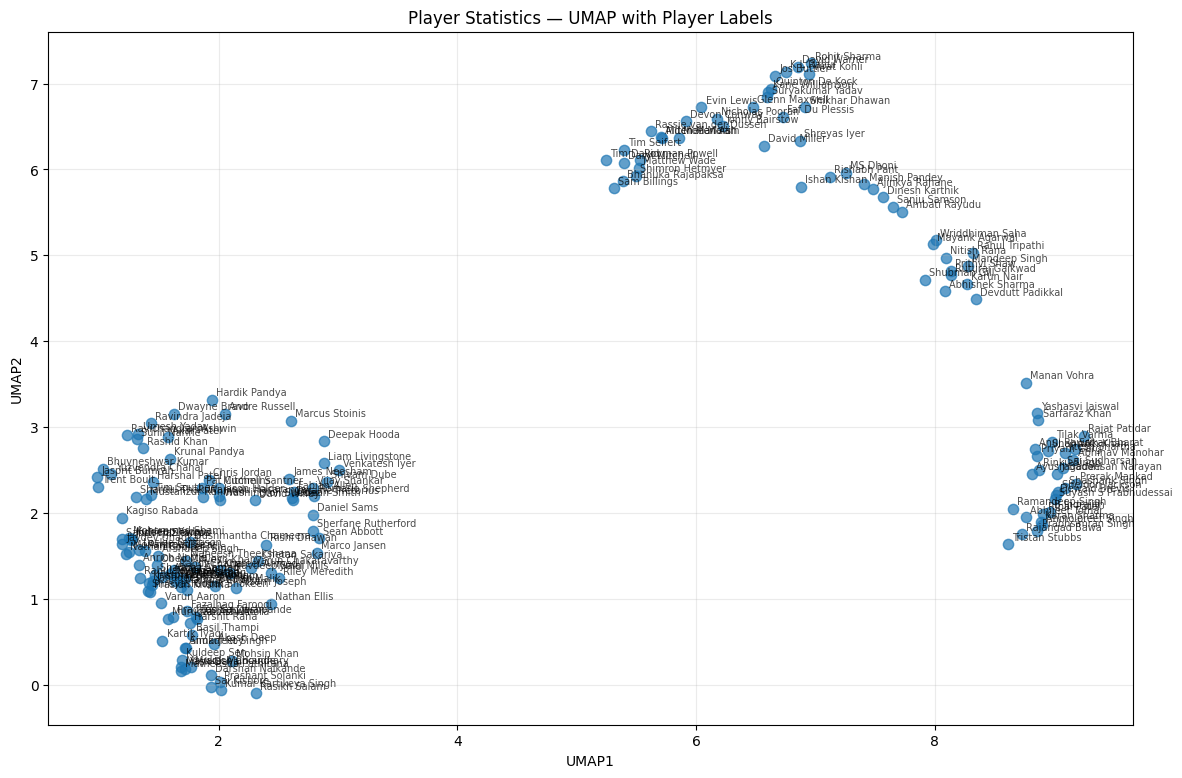

In [ ]:
# ============================================
# STEP 53 — UMAP WITH PLAYER LABELS
# ============================================

plt.figure(figsize=(14, 9))

plt.scatter(
    umap_df["UMAP1"],
    umap_df["UMAP2"],
    s=55,
    alpha=0.7
)

for _, row in umap_df.iterrows():
    plt.annotate(
        row["Player"],
        (row["UMAP1"], row["UMAP2"]),
        fontsize=7,
        alpha=0.7,
        xytext=(3, 3),
        textcoords="offset points"
    )

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("Player Statistics — UMAP with Player Labels")
plt.grid(alpha=0.25)

plt.show()

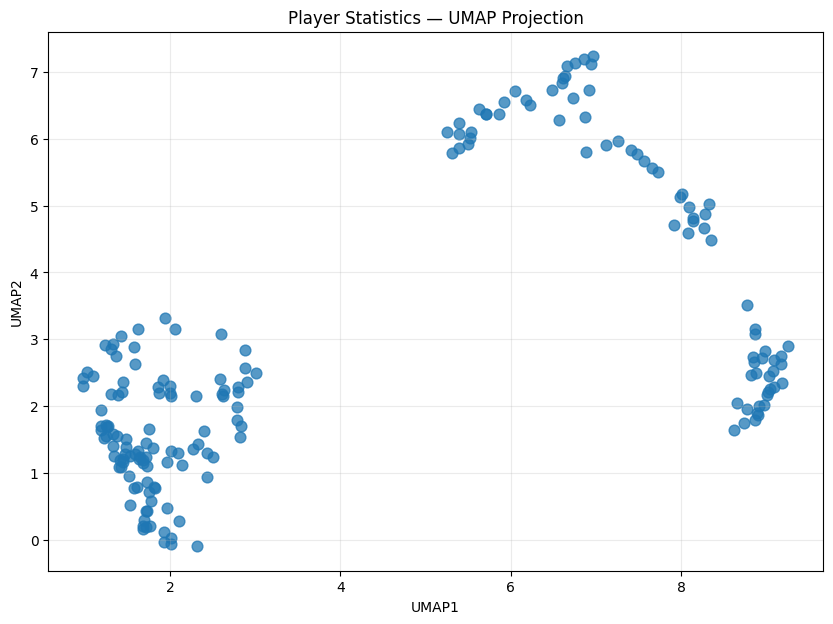

In [ ]:
# ============================================
# STEP 52 — 2D UMAP VISUALIZATION
# ============================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.scatter(
    umap_df["UMAP1"],
    umap_df["UMAP2"],
    s=60,
    alpha=0.75
)

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("Player Statistics — UMAP Projection")
plt.grid(alpha=0.25)

plt.show()

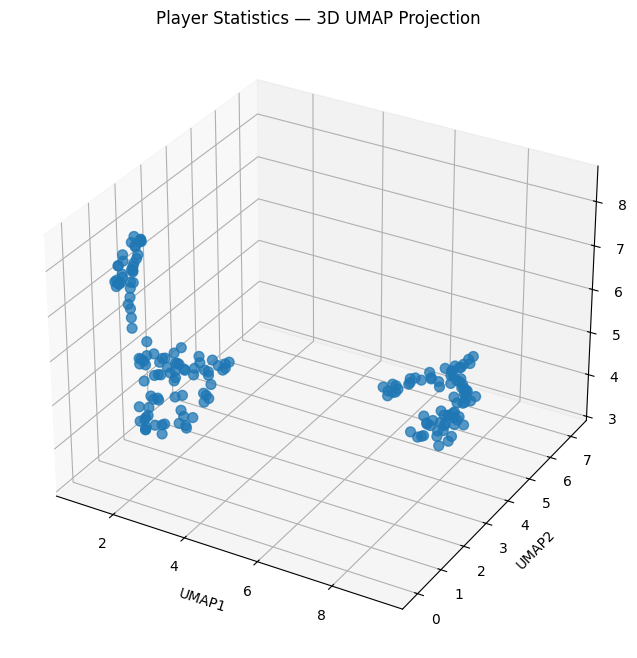

In [ ]:
# ============================================
# STEP 54 — 3D UMAP VISUALIZATION
# ============================================

from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(11, 8))

ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    umap_df["UMAP1"],
    umap_df["UMAP2"],
    umap_df["UMAP3"],
    s=50,
    alpha=0.75
)

ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
ax.set_zlabel("UMAP3")

ax.set_title("Player Statistics — 3D UMAP Projection")

plt.show()

In [ ]:
# ============================================
# STEP 55 — SAVE ML MODELS AS .PKL
# ============================================

import joblib

# Save scaler
joblib.dump(
    scaler,
    "scaler.pkl"
)

# Save PCA model
joblib.dump(
    pca,
    "pca.pkl"
)

# Save UMAP model
joblib.dump(
    umap_model,
    "umap.pkl"
)

# Save the exact feature list used by the models
joblib.dump(
    final_features,
    "feature_columns.pkl"
)

print("✓ scaler.pkl saved")
print("✓ pca.pkl saved")
print("✓ umap.pkl saved")
print("✓ feature_columns.pkl saved")

✓ scaler.pkl saved
✓ pca.pkl saved
✓ umap.pkl saved
✓ feature_columns.pkl saved


In [ ]:
# ============================================
# STEP 56 — VERIFY SAVED FILES
# ============================================

import os

model_files = [
    "scaler.pkl",
    "pca.pkl",
    "umap.pkl",
    "feature_columns.pkl"
]

for file in model_files:
    if os.path.exists(file):
        size_kb = os.path.getsize(file) / 1024
        print(f"✓ {file:<25} {size_kb:.2f} KB")
    else:
        print(f"✗ {file} NOT FOUND")

✓ scaler.pkl                1.69 KB
✓ pca.pkl                   2.25 KB
✓ umap.pkl                  67.21 KB
✓ feature_columns.pkl       0.33 KB
